In [177]:
import numpy as np
import matplotlib.pyplot as plt 
import cv2
import os

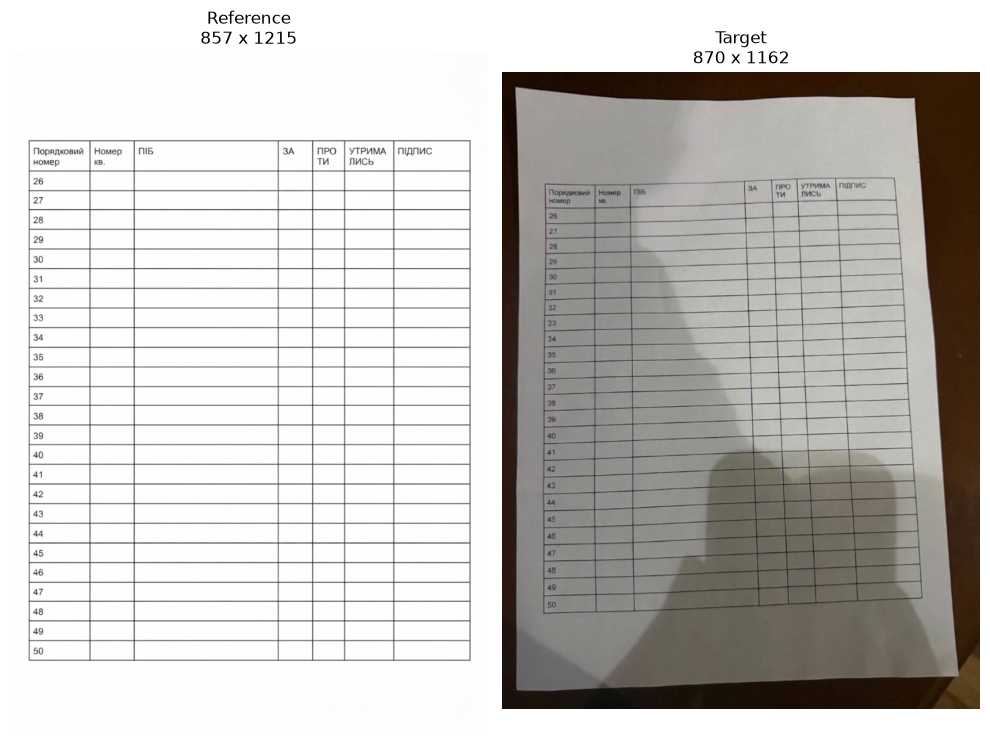

In [146]:
ref = cv2.cvtColor(cv2.imread("src/rectification/reference.png"), cv2.COLOR_BGR2RGB)
tar = cv2.cvtColor(cv2.imread("src/rectification/target.png"), cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 10))
ax[0].imshow(ref)
ax[0].axis("off")
ax[0].set_title(f"Reference\n{ref.shape[1]} x {ref.shape[0]}")
ax[1].imshow(tar)
ax[1].axis("off")
ax[1].set_title(f"Target\n{tar.shape[1]} x {tar.shape[0]}")
fig.tight_layout()
plt.show()

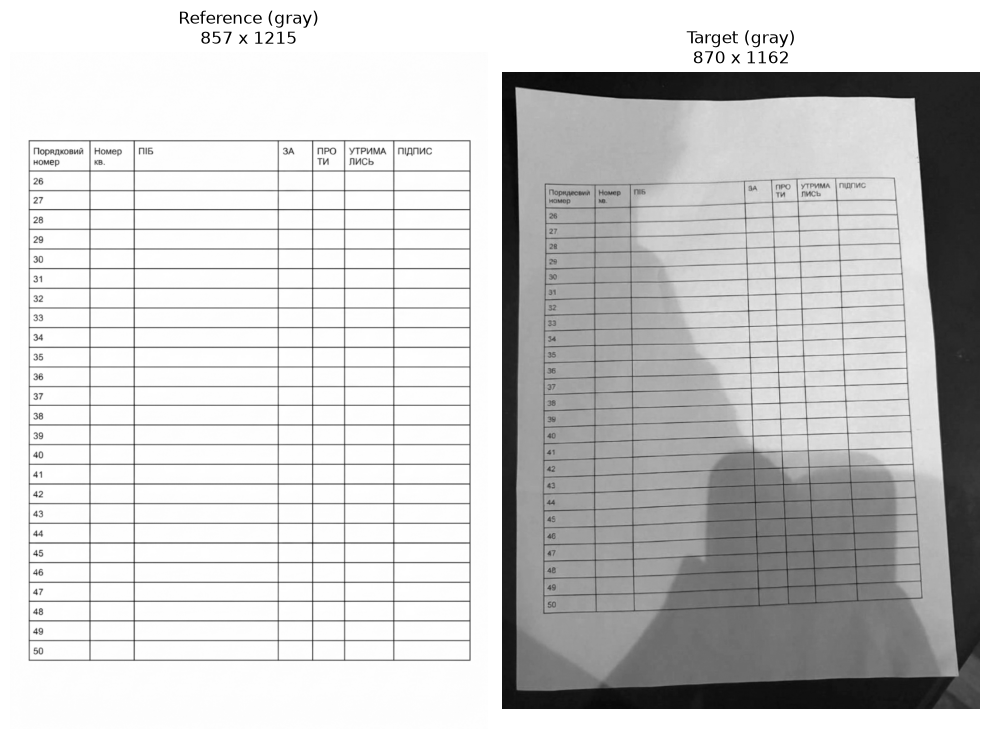

In [147]:
ref_gray = cv2.cvtColor(ref, cv2.COLOR_RGB2GRAY)
tar_gray = cv2.cvtColor(tar, cv2.COLOR_RGB2GRAY)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 10))
ax[0].imshow(ref_gray, cmap="gray")
ax[0].axis("off")
ax[0].set_title(f"Reference (gray)\n{ref_gray.shape[1]} x {ref_gray.shape[0]}")
ax[1].imshow(tar_gray, cmap="gray")
ax[1].axis("off")
ax[1].set_title(f"Target (gray)\n{tar_gray.shape[1]} x {tar_gray.shape[0]}")
fig.tight_layout()
plt.show()

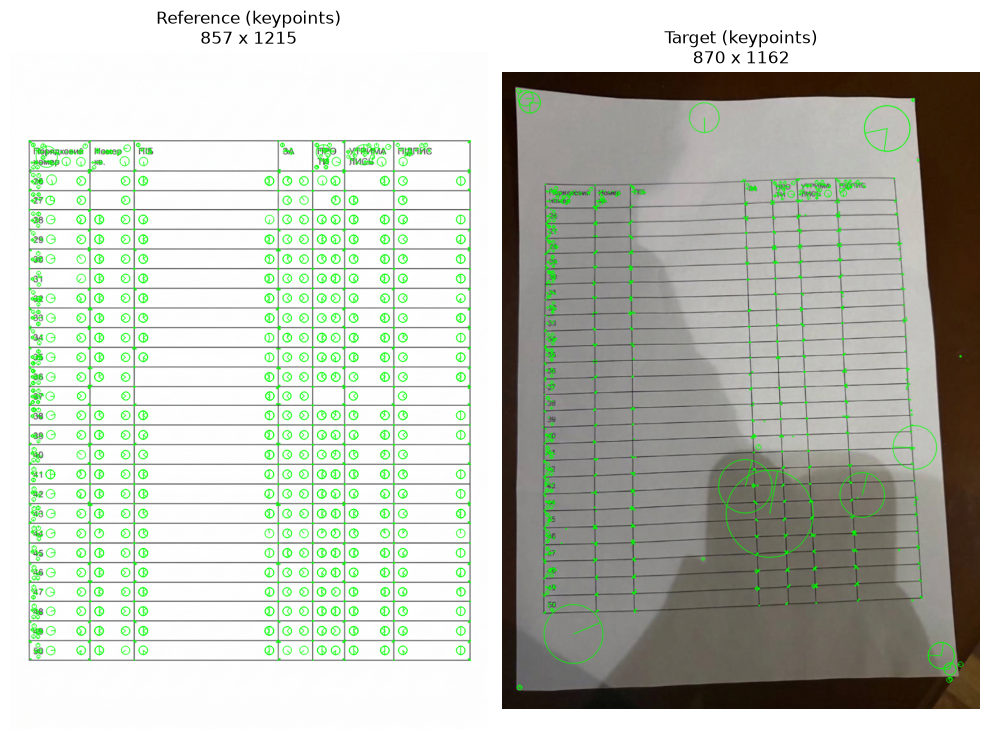

In [148]:
sift = cv2.SIFT_create()
ref_kp, ref_des = sift.detectAndCompute(ref_gray, None)
tar_kp, tar_des = sift.detectAndCompute(tar_gray, None)
bf = cv2.BFMatcher(cv2.NORM_L2)

knn = bf.knnMatch(tar_des, ref_des, k=2)
good = [m for (m, n) in knn if m.distance < 0.7 * n.distance]
ref_kp_img = cv2.drawKeypoints(ref, ref_kp, None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
tar_kp_img = cv2.drawKeypoints(tar, tar_kp, None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 10))
ax[0].imshow(ref_kp_img)
ax[0].axis("off")
ax[0].set_title(f"Reference (keypoints)\n{ref_kp_img.shape[1]} x {ref_kp_img.shape[0]}")
ax[1].imshow(tar_kp_img)
ax[1].axis("off")
ax[1].set_title(f"Target (keypoints)\n{tar_kp_img.shape[1]} x {tar_kp_img.shape[0]}")
fig.tight_layout()
plt.show()

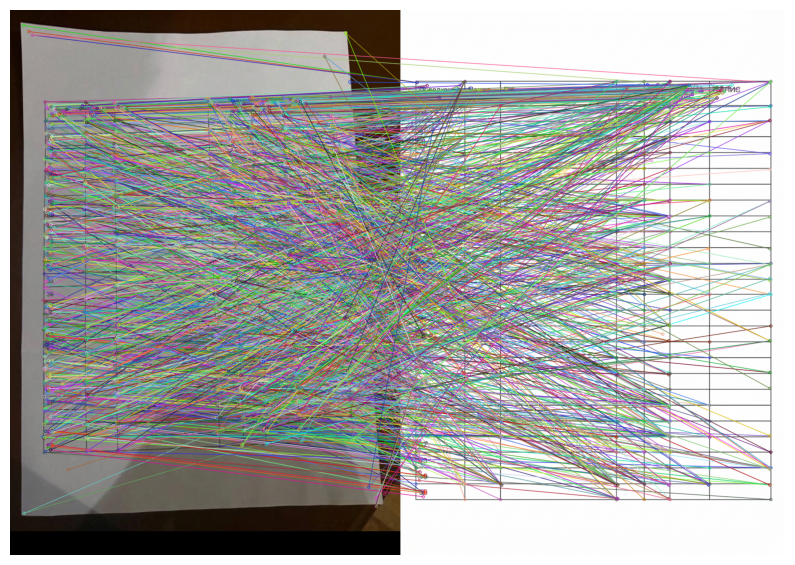

In [149]:
matches = cv2.drawMatches(
    tar, tar_kp, ref, ref_kp, [m for (m, _) in knn], None,
    singlePointColor=(190, 190, 190),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.figure(figsize=(10, 20))
plt.imshow(matches)
plt.axis("off")
plt.show()

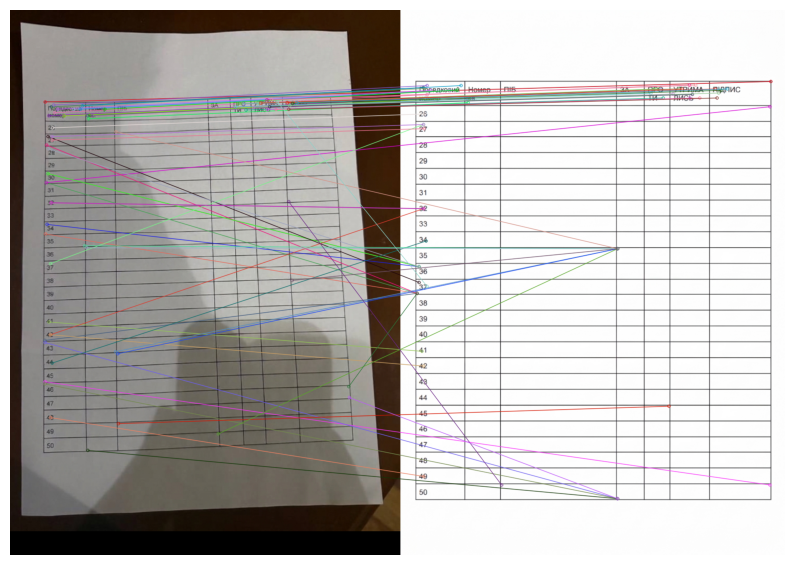

In [150]:
good_matches = cv2.drawMatches(
    tar, tar_kp, ref, ref_kp, good, None,
    singlePointColor=(190, 190, 190),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.figure(figsize=(10, 20))
plt.imshow(good_matches)
plt.axis("off")
plt.show()

Total:     73
Inliers:    41
Outliers:   32


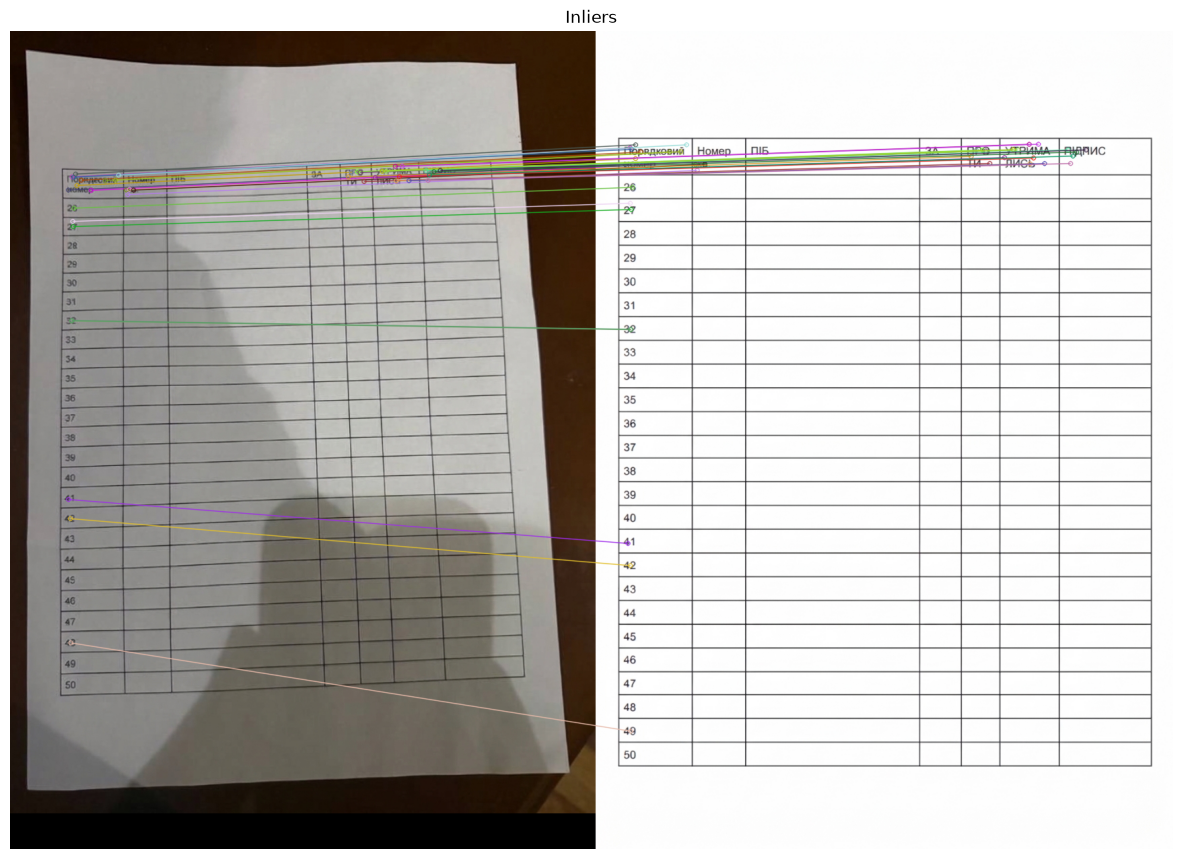

In [172]:
r = np.float32([ref_kp[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
t = np.float32([tar_kp[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)

H, mask = cv2.findHomography(
    t, r,
    method=cv2.RANSAC,
    ransacReprojThreshold=20,
    maxIters=5000,
    confidence=0.995
)

inlier_mask = mask.ravel().astype(bool)
inliers_amount = int(inlier_mask.sum())

print(f"Total:     {len(good)}")
print(f"Inliers:    {inliers_amount}")
print(f"Outliers:   {len(good) - inliers_amount}")

inliers_img = cv2.drawMatches(
    tar, tar_kp, ref, ref_kp,
    [m for m, v in zip(good, inlier_mask) if v], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(15, 25))
plt.imshow(inliers_img)
plt.axis("off")
plt.title("Inliers")
plt.show()

In [175]:
def transform_points(H, pts):
    pts = np.asarray(pts, dtype=float).reshape(-1, 2)
    third = np.ones((pts.shape[0], 1), dtype=float)
    res = np.hstack((pts, third))
    res = (H @ res.T).T 
    return res[:, 0:2] / res[:, 2][:, None]

def warp(img, M, size):
    u, v = np.meshgrid(np.arange(0, size[0]), np.arange(0, size[1]))
    uv = np.hstack((u.ravel()[:, None], v.ravel()[:, None]))
    M_inv = np.linalg.inv(M)
    xy = transform_points(M_inv, uv)
    h, w = img.shape[:2]
    mask = ( ( (xy[:, 0] < w - 1) & (xy[:, 0] >= 0) ) & ( (xy[:, 1] < h - 1) & (xy[:, 1] >= 0) ) )
    x = np.floor(xy[mask][:, 0]).astype(int)
    y = np.floor(xy[mask][:, 1]).astype(int)
    dx = xy[mask][:, 0] - x
    dy = xy[mask][:, 1] - y
    if img.ndim == 2:
        sampled = (
            (1 - dx) * (1 - dy) * img[y, x] +
            dx * (1 - dy) * img[y, x + 1] +
            dx * dy * img[y + 1, x + 1] + 
            (1 - dx) * dy * img[y + 1, x]
        )
    if img.ndim == 3:
        sampled = (
            (1 - dx)[:, None] * (1 - dy)[:, None] * img[y, x] +
            dx[:, None] * (1 - dy)[:, None] * img[y, x + 1] +
            dx[:, None] * dy[:, None] * img[y + 1, x + 1] + 
            (1 - dx)[:, None] * dy[:, None] * img[y + 1, x]
        )
    out = np.zeros((size[0] * size[1], *img.shape[2:]), dtype=float)
    out[mask] = sampled
    return out.reshape(size[1], size[0], *img.shape[2:])

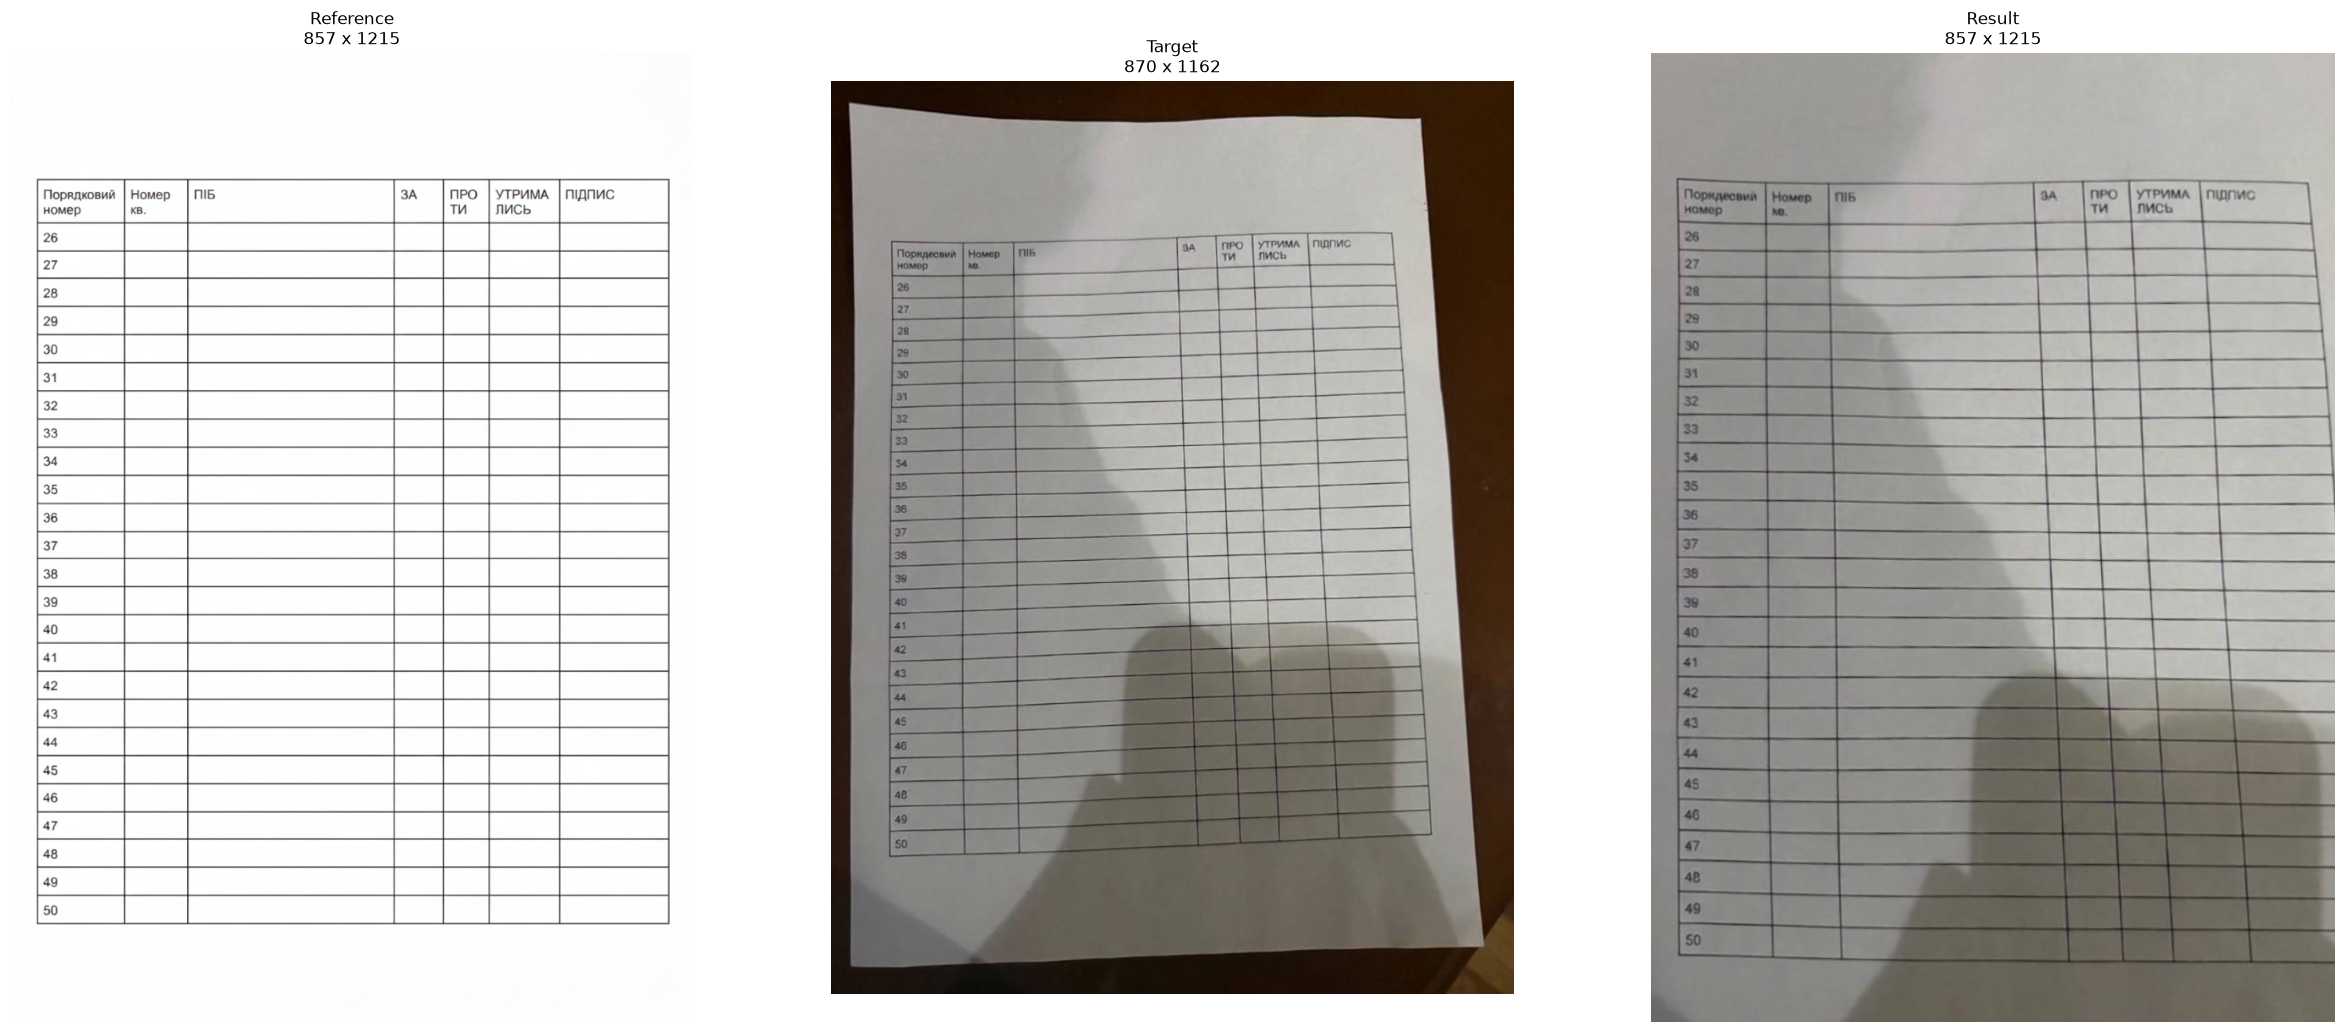

In [179]:
res = warp(tar, H, (ref.shape[1], ref.shape[0])).astype(np.uint8)
os.makedirs("outputs", exist_ok=True)
plt.imsave("outputs/lab_rectification.png", res)

fix, ax = plt.subplots(nrows=1, ncols=3, figsize=(30, 30))
ax[0].imshow(ref)
ax[0].axis("off")
ax[0].set_title(f"Reference\n{ref.shape[1]} x {ref.shape[0]}")
ax[1].imshow(tar)
ax[1].axis("off")
ax[1].set_title(f"Target\n{tar.shape[1]} x {tar.shape[0]}")
ax[2].imshow(res)
ax[2].axis("off")
ax[2].set_title(f"Result\n{res.shape[1]} x {res.shape[0]}")
fig.tight_layout()
plt.show()